In [1]:
import seaborn

from astropy import units

from realistic import load_realistic_timeseries
from self_lensing import DEFAULTS, default_times, SelfLensingSystem, LensingEvent

In [2]:
rts = load_realistic_timeseries()

In [3]:
peak_time = default_times[0]

In [4]:
idx = 5000
ts = rts.iloc[idx]

In [5]:
ts

a                                                                0.1
e                                                                0.6
periapsis_phase                                             1.396263
Macc                                                       17.788889
Porb                                                        2.664697
Mcomp                                                            1.0
Rcomp                                                            1.0
b                                                                0.0
rv                 [369.35938450590646, 529342.0388585406, -22187...
rv_err                                                     500.09999
times              [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...
RV accuracy                                                    500.0
cadence                                                            1
pristine idx                                                     625
Name: 625, dtype: object

In [6]:
sls, sampler = SelfLensingSystem.from_rv_fit(
    ts['rv'] * units.m / units.s,
    ts['rv_err'] * units.m / units.s,
    DEFAULTS['start_time'] + ts['times'] * units.day,
    Mcomp=DEFAULTS['Mcomp'],
    Rcomp=DEFAULTS['Rcomp'],
    peak_time=DEFAULTS['start_time'],
    Teff=DEFAULTS['Teff'],
)

100%|██████████| 5000/5000 [02:02<00:00, 40.73it/s]


In [7]:
import numpy
numpy.median(sampler.get_chain(flat=True, discard=100), axis=0)

array([0.73459997, 1.50279401, 0.69331511, 1.57123978])

In [8]:
# sls.a = 1 * units.AU
le = LensingEvent(sls, DEFAULTS['start_time'])

In [9]:
sls.a, sls.Macc, sls.e, sls.periapsis_phase, sls.porb

(<Quantity 0.09993455 AU>,
 <Quantity 17.74983117 solMass>,
 <Quantity 0.03489356>,
 <Quantity 3.51286563 rad>,
 <Quantity 2.66485273 d>)

<Axes: xlabel='times', ylabel='rv'>

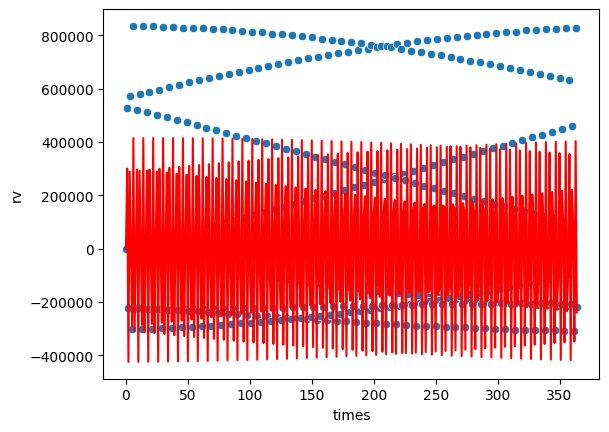

In [10]:
seaborn.scatterplot(ts.to_dict(), x='times', y='rv')
seaborn.lineplot({'times': default_times, 'rv': le.rv_range(DEFAULTS['start_time'], DEFAULTS['end_time'])}, x='times', y='rv', color='red')

Text(0.5, 0, 'step number')

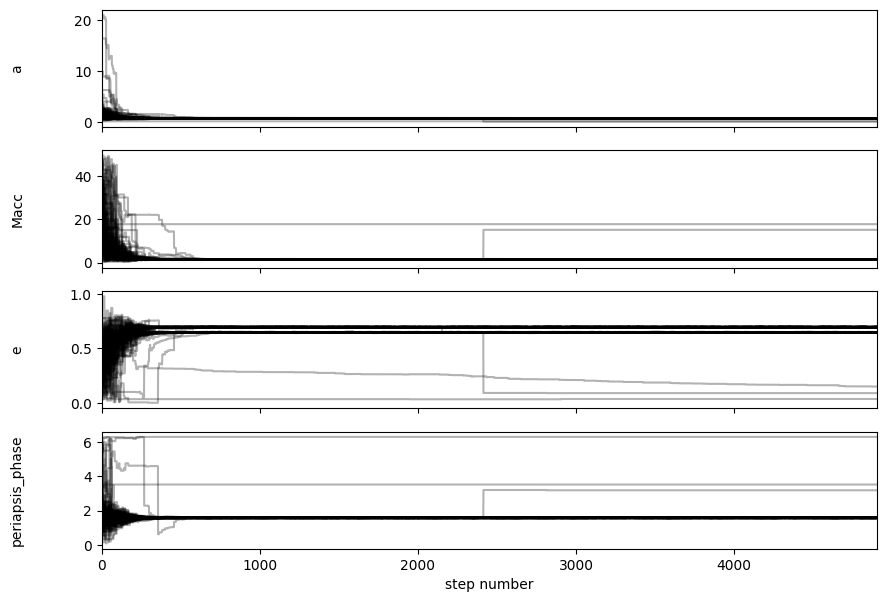

In [11]:
from matplotlib import pyplot as plt
labels = ["a", "Macc", 'e', 'periapsis_phase']
fig, axes = plt.subplots(len(labels), figsize=(10, 7), sharex=True)
samples = sampler.get_chain(discard=100)
flat_samples = sampler.get_chain(flat=True)
for i in range(len(labels)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")

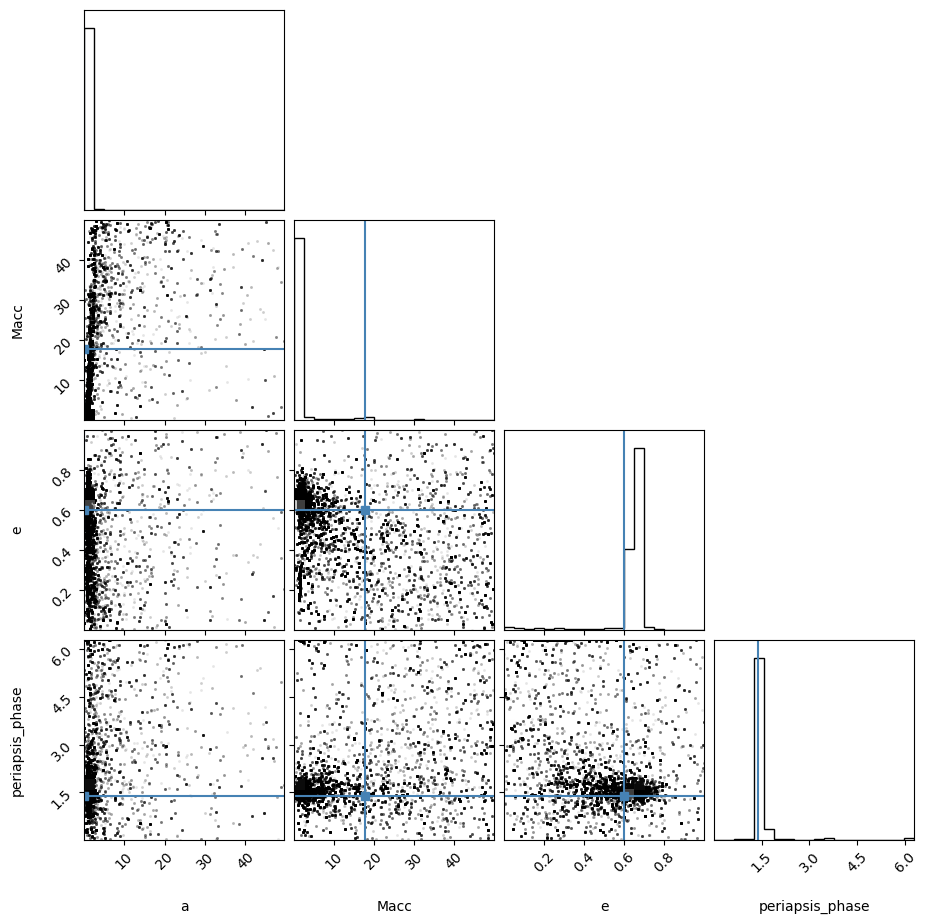

In [12]:
import corner

fig = corner.corner(
    flat_samples, labels=labels, truths=[ts['a'], ts['Macc'], ts['e'], ts['periapsis_phase']]
)